**Projet SID**

 **Étape 1 — Analyse exploratoire des données**

In [ ]:
!pip install -q gdown #sert à installer un outil qui permet de télécharger des fichiers depuis Google Drive vers Google Cola

In [ ]:
# Supprimer l'ancienne copie du fichier ZIP dans Colab, si elle existe
!rm -f PROJET_SID_2026.zip

# Télécharger le fichier depuis Google Drive et l'enregistrer sous le nom PROJET_SID_2026.zip
!gdown --fuzzy "https://drive.google.com/file/d/1ykUsEsbMoMlsji4eewSPVgUgqjT98GJH/view?usp=drive_link" -O PROJET_SID_2026.zip

Downloading...
From (original): https://drive.google.com/uc?id=1ykUsEsbMoMlsji4eewSPVgUgqjT98GJH
From (redirected): https://drive.google.com/uc?id=1ykUsEsbMoMlsji4eewSPVgUgqjT98GJH&confirm=t&uuid=f85c9360-d2d8-405e-89e3-810f4377fc6d
To: /content/PROJET_SID_2026.zip
100% 4.00G/4.00G [00:36<00:00, 109MB/s]


In [ ]:
# Créer le dossier /content/data s'il n'existe pas déjà
!mkdir -p /content/data

# Décompresser l'archive ZIP dans le dossier /content/data
!unzip -q /content/PROJET_SID_2026.zip -d /content/data

In [ ]:
!ls /content/data
!ls /content/data/*

__MACOSX  PROJET_SID_2026
/content/data/__MACOSX:
PROJET_SID_2026

/content/data/PROJET_SID_2026:
movie


In [ ]:
# Importer le module os pour interagir avec les fichiers et dossiers
import os

# Définir le chemin du dossier contenant les données des films
ROOT = "/content/data/PROJET_SID_2026/movie"

# Afficher la liste des fichiers et dossiers présents dans ce répertoire
print(os.listdir(ROOT))

['.DS_Store', 'audio', 'annotation', 'video']


In [ ]:
# Parcourir les trois sous-dossiers du projet
for sub in ["annotation", "audio", "video"]:

    # Construire le chemin complet du sous-dossier
    p = f"{ROOT}/{sub}"

    # Vérifier que le sous-dossier existe
    if os.path.exists(p):

        # Récupérer les éléments directement présents dans ce sous-dossier
        films = os.listdir(p)

        # Compter tous les fichiers présents dans ce dossier et ses sous-dossiers
        n_files = sum(len(fs) for _, _, fs in os.walk(p))

        # Afficher le nom du sous-dossier, le nombre d'éléments directs et le nombre total de fichiers
        print(sub, "| dossiers (films):", len(films), "| fichiers:", n_files)

annotation | dossiers (films): 350 | fichiers: 3088
audio | dossiers (films): 350 | fichiers: 3088
video | dossiers (films): 351 | fichiers: 3089


In [ ]:
# Afficher les éléments directement présents dans le dossier vidéo
p = f"{ROOT}/video"

for element in os.listdir(p):
    chemin = os.path.join(p, element)

    # Afficher les éléments qui ne sont pas des dossiers
    if not os.path.isdir(chemin):
        print("Élément qui n'est pas un dossier :", element)

Élément qui n'est pas un dossier : .DS_Store


In [ ]:
# Importer la bibliothèque glob pour rechercher des fichiers
import glob

# Parcourir les trois dossiers du projet : annotations, audio et vidéo
for sub in ["annotation", "audio", "video"]:

    # Rechercher tous les fichiers dans le dossier et ses sous-dossiers
    # ROOT correspond au chemin principal du projet
    # **/*.* permet de rechercher les fichiers dans tous les sous-dossiers
    # recursive=True autorise la recherche récursive
    fichiers = glob.glob(f"{ROOT}/{sub}/**/*.*", recursive=True)

    # Afficher le nom du dossier et les 3 premiers chemins trouvés
    # [:3] permet de limiter l'affichage aux 3 premiers fichiers
    print(sub, fichiers[:3])

annotation ['/content/data/PROJET_SID_2026/movie/annotation/00306/00306_clip_013.json', '/content/data/PROJET_SID_2026/movie/annotation/00306/00306_clip_004.json', '/content/data/PROJET_SID_2026/movie/annotation/00306/00306_clip_003.json']
audio ['/content/data/PROJET_SID_2026/movie/audio/00306/00306_clip_013.mp3', '/content/data/PROJET_SID_2026/movie/audio/00306/00306_clip_004.mp3', '/content/data/PROJET_SID_2026/movie/audio/00306/00306_clip_006.mp3']
video ['/content/data/PROJET_SID_2026/movie/video/00306/00306_clip_007.mp4', '/content/data/PROJET_SID_2026/movie/video/00306/00306_clip_013.mp4', '/content/data/PROJET_SID_2026/movie/video/00306/00306_clip_011.mp4']


In [ ]:
# Importer les bibliothèques nécessaires
import json       # Lire les fichiers au format JSON
import glob       # Rechercher des fichiers à partir d'un chemin
import pandas as pd  # Manipuler les données sous forme de tableau
import os         # Manipuler les chemins et les noms de dossiers

# Définir le chemin du dossier principal du projet
ROOT = "/content/data/PROJET_SID_2026/movie"

# Créer une liste vide pour stocker les annotations
rows = []

# Rechercher tous les fichiers JSON dans les sous-dossiers de annotation
# Exemple : annotation/00306/00306_clip_013.json
for f in glob.glob(ROOT + "/annotation/*/*.json"):

    # Ouvrir le fichier JSON
    with open(f) as fichier:

        # Lire son contenu et le convertir en dictionnaire Python
        d = json.load(fichier)

    # Ajouter le numéro du film à partir du nom du dossier parent
    d["film"] = os.path.basename(os.path.dirname(f))

    # Ajouter les informations de cette annotation à la liste
    rows.append(d)

# Transformer la liste de dictionnaires en tableau Pandas
df = pd.DataFrame(rows)

# Afficher les dimensions du tableau : nombre de lignes et de colonnes
print(df.shape)

# Compter le nombre de films différents dans le tableau
print("Nombre de films :", df["film"].nunique())

# Afficher les 5 premières lignes du tableau
df.head()

(3088, 8)
Nombre de films : 350


,video_id,brightness,colorfulness,hue,emotion,caption,duration,film
0,00306_clip_013,0.3,0.2,18,excitement,The video shows a brown and white dog standing...,15.68,00306
1,00306_clip_004,0.2,0.2,16,contentment,The video shows a boy lying in bed with a dog....,21.68,00306
2,00306_clip_003,0.2,0.2,15,contentment,The video shows a dog lying on a bed with a pe...,4.84,00306
3,00306_clip_001,0.2,0.2,17,contentment,"The video shows a dog standing in a bedroom, l...",6.01,00306
4,00306_clip_007,0.2,0.2,18,disgust,The video shows a man and a woman standing in ...,13.01,00306


In [ ]:
# Ajouter une colonne pour vérifier la présence de la vidéo de chaque clip
df["has_video"] = df.apply(
    lambda r: os.path.exists(f"{ROOT}/video/{r.film}/{r.video_id}.mp4"),
    axis=1
)

# Ajouter une colonne pour vérifier la présence de l'audio de chaque clip
df["has_audio"] = df.apply(
    lambda r: os.path.exists(f"{ROOT}/audio/{r.film}/{r.video_id}.mp3"),
    axis=1
)

# Compter les combinaisons de présence ou d'absence des fichiers
print(df[["has_video", "has_audio"]].value_counts())

has_video  has_audio
True       True         3088
Name: count, dtype: int64


Cela signifie que les 3 088 clips annotés possèdent tous une vidéo et un fichier audio correspondant, selon les chemins vérifiés par ton code.

emotion
anger          677
fear           519
contentment    373
excitement     354
sadness        338
disgust        297
awe            286
amusement      244
Name: count, dtype: int64
emotion
amusement       96
anger          223
awe            120
contentment    140
disgust        146
excitement     151
fear           171
sadness        133
Name: film, dtype: int64


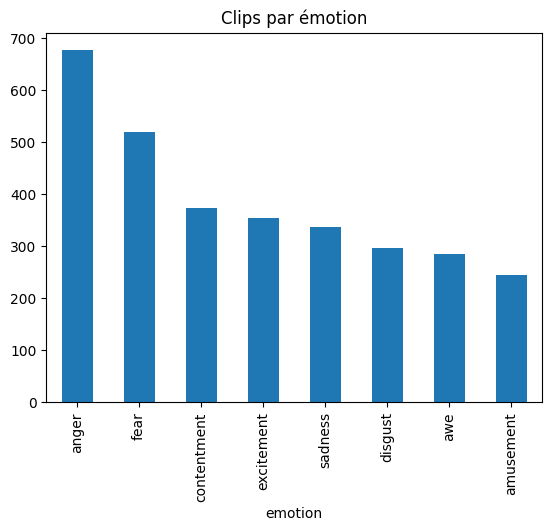

In [ ]:
# Importer la bibliothèque pour créer des graphiques
import matplotlib.pyplot as plt

# Compter le nombre de clips pour chaque émotion
print(df["emotion"].value_counts())

# Compter le nombre de films différents contenant chaque émotion
print(df.groupby("emotion")["film"].nunique())

# Créer un diagramme en barres montrant le nombre de clips par émotion
df["emotion"].value_counts().plot(
    kind="bar",
    title="Clips par émotion"
)

# Afficher le graphique
plt.show()

### Classement des émotions par nombre de clips

| Émotion | Nombre approximatif de clips |
|---|---:|
| Anger (colère) | 678 |
| Fear (peur) | 520 |
| Contentment (satisfaction) | 375 |
| Excitement (enthousiasme) | 355 |
| Sadness (tristesse) | 337 |
| Disgust (dégoût) | 296 |
| Awe (émerveillement) | 285 |
| Amusement (amusement) | 242 |

**Interprétation :** l’émotion *anger* est la plus représentée, tandis que *amusement* est la moins représentée. La répartition des clips entre les huit classes est donc déséquilibrée.

In [ ]:
# Afficher le nombre de valeurs manquantes dans chaque colonne
print("Valeurs manquantes par colonne :")
print(df.isnull().sum())

# Compter le nombre de lignes entièrement identiques
print("\nNombre de lignes dupliquées :", df.duplicated().sum())

# Vérifier si certains identifiants de clips apparaissent plusieurs fois
print("Nombre de video_id dupliqués :", df["video_id"].duplicated().sum())

Valeurs manquantes par colonne :
video_id        0
brightness      0
colorfulness    0
hue             0
emotion         0
caption         0
duration        0
film            0
has_video       0
has_audio       0
dtype: int64

Nombre de lignes dupliquées : 0
Nombre de video_id dupliqués : 0


### Vérification de la qualité des annotations

| Vérification | Résultat | Interprétation |
|---|---:|---|
| Valeurs manquantes | 0 dans toutes les colonnes | Aucune valeur manquante détectée. |
| Lignes entièrement dupliquées | 0 | Aucune ligne entièrement identique détectée. |
| Identifiants `video_id` dupliqués | 0 | Chaque identifiant de clip apparaît une seule fois. |
| Présence des vidéos | 3 088 sur 3 088 | Toutes les vidéos associées aux annotations ont été trouvées. |
| Présence des audios | 3 088 sur 3 088 | Tous les fichiers audio associés ont été trouvés. |

**Conclusion :** les vérifications effectuées ne révèlent aucune valeur manquante, aucun doublon complet ni aucun identifiant de clip dupliqué. Les fichiers audio et vidéo associés aux annotations sont également présents. Ces résultats sont favorables à la poursuite de l’analyse exploratoire des données.

**Suite de l’EDA : analyser les variables numériques**

In [ ]:
# Afficher les statistiques descriptives des variables numériques
print(df[["duration", "brightness", "colorfulness", "hue"]].describe())

          duration   brightness  colorfulness          hue
count  3088.000000  3088.000000   3088.000000  3088.000000
mean      8.141580     0.205894      0.336723    75.412565
std       4.737166     0.108279      0.143079    92.643565
min       4.000000     0.000000      0.100000     0.000000
25%       4.960000     0.100000      0.200000    21.000000
50%       6.420000     0.200000      0.300000    31.000000
75%       9.432500     0.300000      0.400000    73.000000
max      29.820000     0.600000      1.000000   359.000000


**Tableau d’interprétation des variables numériques**

### Analyse descriptive des variables numériques

| Variable | Moyenne | Médiane | Minimum | Maximum | Interprétation |
|---|---:|---:|---:|---:|---|
| `duration` | 8,14 s | 6,42 s | 4,00 s | 29,82 s | Les clips durent en moyenne 8,14 secondes. La moitié des clips dure moins de 6,42 secondes. |
| `brightness` | 0,206 | 0,200 | 0,000 | 0,600 | La luminosité moyenne est d’environ 0,21, avec des valeurs comprises entre 0 et 0,60. |
| `colorfulness` | 0,337 | 0,300 | 0,100 | 1,000 | La colorimétrie moyenne est d’environ 0,34, avec une variabilité entre les clips. |
| `hue` | 75,41° | 31° | 0° | 359° | La teinte couvre presque tout l’intervalle de valeurs possibles, de 0° à 359°. |

**Conclusion :** les clips ont des durées variables, avec une moyenne supérieure à la médiane, ce qui suggère une distribution asymétrique vers les durées les plus longues. Les variables de luminosité et de colorimétrie présentent également une certaine variabilité. La teinte couvre presque tout le cercle chromatique.

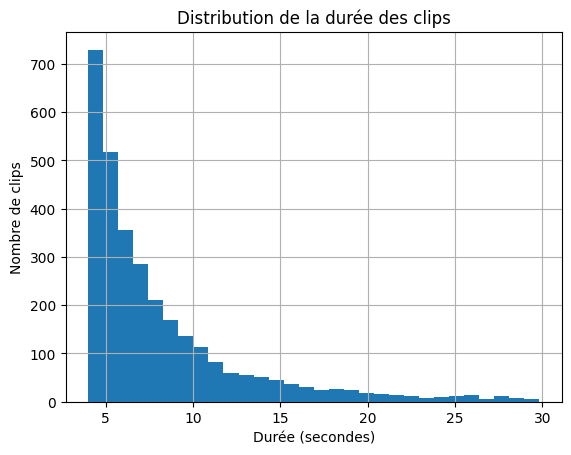

In [ ]:
import matplotlib.pyplot as plt

# Créer un histogramme des durées des clips
df["duration"].hist(bins=30)

# Ajouter un titre et les noms des axes
plt.title("Distribution de la durée des clips")
plt.xlabel("Durée (secondes)")
plt.ylabel("Nombre de clips")

# Afficher le graphique
plt.show()

**Observation :** l’histogramme montre que les clips de courte durée sont les plus nombreux. À mesure que la durée augmente, le nombre de clips observés diminue globalement. La distribution est donc asymétrique à droite, avec quelques clips de durée plus élevée. Plus la durée des clips augmente, moins ils sont nombreux. La distribution est asymétrique à droite.

**La suite de notre analyse exploratoire (EDA) est d’étudier la distribution des variables visuelles brightness (luminosité) et colorfulness (colorimétrie).**

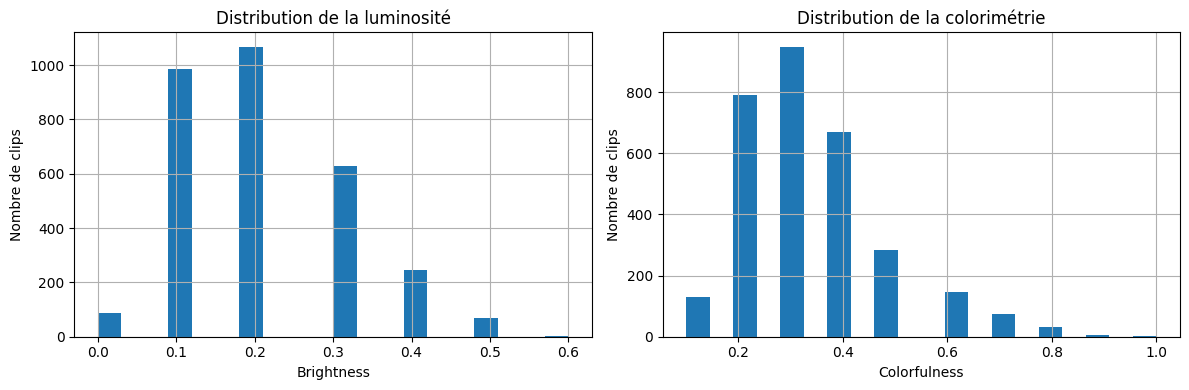

In [ ]:
# Créer deux graphiques côte à côte
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogramme de la luminosité
df["brightness"].hist(bins=20, ax=axes[0])
axes[0].set_title("Distribution de la luminosité")
axes[0].set_xlabel("Brightness")
axes[0].set_ylabel("Nombre de clips")

# Histogramme de la colorimétrie
df["colorfulness"].hist(bins=20, ax=axes[1])
axes[1].set_title("Distribution de la colorimétrie")
axes[1].set_xlabel("Colorfulness")
axes[1].set_ylabel("Nombre de clips")

# Ajuster l'affichage et montrer les graphiques
plt.tight_layout()
plt.show()

**Observations :**
- **Luminosité (`brightness`) :** la majorité des clips ont une luminosité comprise entre 0,1 et 0,3.
- **Colorimétrie (`colorfulness`) :** la plupart des clips présentent des valeurs comprises entre 0,2 et 0,4. Les clips très colorés sont moins nombreux.

**La suite de l’EDA sera d’étudier la distribution de la variable hue (teinte), puis nous pourrons examiner les relations entre les variables.**

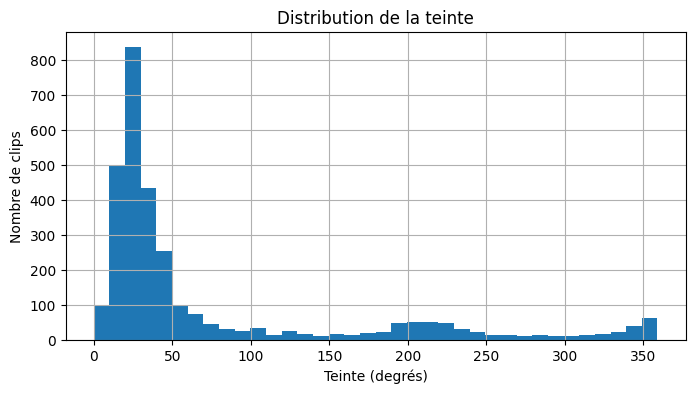

In [ ]:
# Créer un histogramme de la teinte
df["hue"].hist(bins=36, figsize=(8, 4))

# Ajouter le titre et les noms des axes
plt.title("Distribution de la teinte")
plt.xlabel("Teinte (degrés)")
plt.ylabel("Nombre de clips")

# Afficher le graphique
plt.show()

**Observation :** Les teintes sont principalement concentrées entre 10° et 50°, avec un pic autour de 25°. D’autres teintes sont moins fréquentes, notamment autour de 200° à 230°.


**Suite de l’EDA : étudier les relations entre les variables**

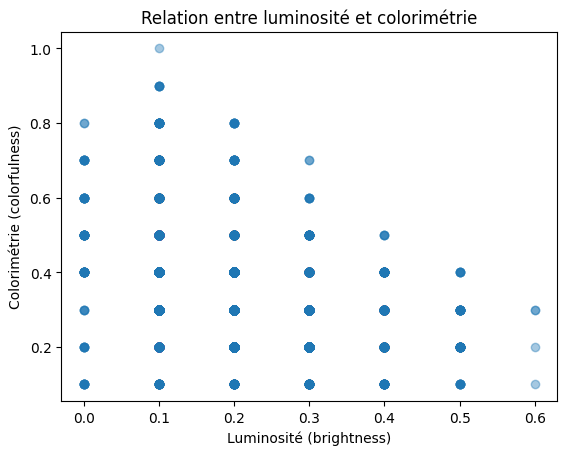

In [ ]:
# Créer un nuage de points entre luminosité et colorimétrie
plt.scatter(df["brightness"], df["colorfulness"], alpha=0.4)

# Ajouter le titre et les noms des axes
plt.title("Relation entre luminosité et colorimétrie")
plt.xlabel("Luminosité (brightness)")
plt.ylabel("Colorimétrie (colorfulness)")

# Afficher le graphique
plt.show()

**Observation :** Le graphique ne montre pas de relation linéaire nette entre la luminosité et la colorimétrie. Les valeurs sont regroupées sur plusieurs niveaux discrets.

**Suite de l’EDA : calculer la corrélation**

In [ ]:
# Calculer la corrélation entre luminosité et colorimétrie
correlation = df["brightness"].corr(df["colorfulness"])

# Afficher le résultat
print("Corrélation entre luminosité et colorimétrie :", round(correlation, 3))

Corrélation entre luminosité et colorimétrie : -0.354


**Observation :** Le coefficient de corrélation est de **−0,354**, ce qui indique une relation linéaire négative modérée entre la luminosité et la colorimétrie. Globalement, les clips plus lumineux tendent à présenter des valeurs de colorimétrie plus faibles, sans que cette relation soit systématique.

**Pour la suite de l’EDA**
**nous pouvons maintenant étudier la relation entre les variables visuelles et les émotions, pour voir si certaines caractéristiques varient selon la classe émotionnelle.**

In [ ]:
# Calculer la luminosité et la colorimétrie moyennes pour chaque émotion
print(df.groupby("emotion")[["brightness", "colorfulness"]].mean().round(3))

             brightness  colorfulness
emotion                              
amusement         0.203         0.371
anger             0.220         0.342
awe               0.198         0.330
contentment       0.209         0.308
disgust           0.228         0.326
excitement        0.227         0.340
fear              0.180         0.336
sadness           0.181         0.344


**Observations :**

Luminosité : les clips de dégoût et d’enthousiasme présentent les moyennes les plus élevées, tandis que ceux de peur et de tristesse présentent les plus faibles.

Colorimétrie : l’amusement possède la moyenne la plus élevée, tandis que la satisfaction présente la plus faible.

Les différences entre les moyennes restent relativement limitées. Ces variables seules ne suffisent donc pas à distinguer clairement les huit émotions.

**Comparer la luminosité et la colorimétrie selon les émotions avec boxplots**

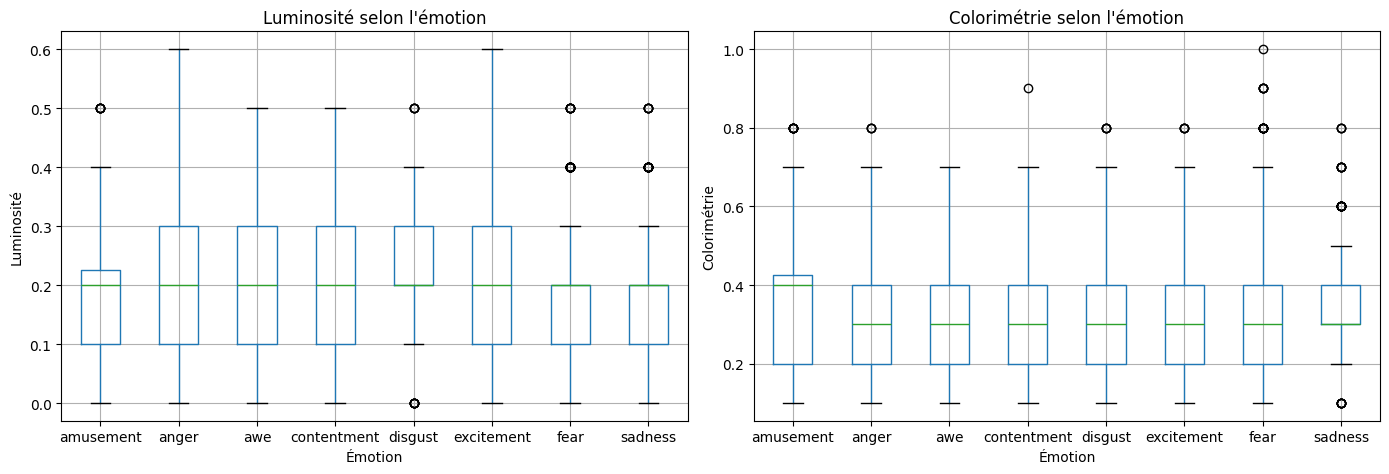

In [ ]:
# Créer deux graphiques côte à côte
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Comparer la luminosité selon les émotions
df.boxplot(column="brightness", by="emotion", ax=axes[0])
axes[0].set_title("Luminosité selon l'émotion")
axes[0].set_xlabel("Émotion")
axes[0].set_ylabel("Luminosité")

# Comparer la colorimétrie selon les émotions
df.boxplot(column="colorfulness", by="emotion", ax=axes[1])
axes[1].set_title("Colorimétrie selon l'émotion")
axes[1].set_xlabel("Émotion")
axes[1].set_ylabel("Colorimétrie")

# Supprimer les titres automatiques ajoutés par Pandas
plt.suptitle("")

# Ajuster l'espacement et afficher les graphiques
plt.tight_layout()
plt.show()

**Observation :**
**Analyse des distributions selon les émotions**

Les boîtes à moustaches montrent que les distributions de luminosité et de colorimétrie se chevauchent fortement entre les différentes émotions. La luminosité médiane est globalement proche de 0,2, tandis que la colorimétrie médiane est généralement proche de 0,3, avec une valeur plus élevée pour l’amusement. Certaines valeurs atypiques sont également observées. Ces caractéristiques visuelles peuvent apporter des informations utiles, mais elles ne suffisent pas, à elles seules, à distinguer clairement les émotions.

In [ ]:
# Afficher les catégories d'émotions présentes
print("Émotions présentes :", sorted(df["emotion"].unique()))

# Vérifier les durées négatives ou nulles
print("Durées nulles ou négatives :", (df["duration"] <= 0).sum())

# Vérifier les durées manquantes
print("Durées manquantes :", df["duration"].isna().sum())

Émotions présentes : ['amusement', 'anger', 'awe', 'contentment', 'disgust', 'excitement', 'fear', 'sadness']
Durées nulles ou négatives : 0
Durées manquantes : 0


**Vérification de la qualité des données**

Les huit classes d’émotions attendues sont présentes dans le jeu de données. Aucune durée n’est manquante ou nulle ou négative. Ces vérifications ne révèlent donc pas d’anomalie sur ces critères.

**Conclusion générale de l’analyse exploratoire**

L’analyse exploratoire du jeu de données a permis de mieux comprendre sa structure et ses principales caractéristiques. Le jeu de données contient **3 088 clips vidéo répartis en 8 catégories d’émotions**, avec les fichiers audio et vidéo correspondants disponibles pour chaque annotation.

L’étude de la répartition des émotions a révélé un **déséquilibre entre les classes** : la colère (*anger*) est la plus représentée, tandis que l’amusement (*amusement*) est la moins représentée. L’analyse des durées montre que la majorité des clips sont relativement courts, généralement entre 4 et 8 secondes.

L’étude des caractéristiques visuelles indique que la luminosité et la colorimétrie varient selon les clips, mais que leurs distributions se chevauchent fortement entre les émotions. Ces variables peuvent donc fournir des informations utiles, sans permettre à elles seules de distinguer clairement toutes les catégories émotionnelles.

Enfin, les vérifications de qualité n’ont révélé aucune valeur manquante dans les variables étudiées, aucun doublon parmi les identifiants des clips, ni aucune durée nulle ou négative. Les huit catégories d’émotions attendues sont également présentes.

**En conclusion, cette analyse exploratoire fournit une première compréhension du jeu de données et met en évidence certains points importants, notamment le déséquilibre des classes et la variabilité des caractéristiques visuelles.** Ces observations serviront de base pour la suite du projet, consacré à la reconnaissance des émotions à partir des données multimédias (texte, audio et vidéo).